# Tarea 4: Notebook de métricas de clasificación
Datos: `bank-additional-full.csv` (Moro et al., 2014). La variable objetivo es `y` (si el cliente acepta el depósito a plazo). Cada punto tiene su código y su respuesta.

En esta actividad se aborda el problema de clasificación basado en regresión logística, empleando el conjunto de datos Bank Marketing (Moro et al., 2014) del repositorio de la UCI. Dicho dataset busca anticipar si un usuario hara un depósito a plazo fijo a partir de sus antecedentes financieros. La etiqueta de interés es y, la cual indica "yes" si el cliente acepta la oferta o "no" en caso contrario. Mediante este modelo se calculará la probabilidad de aceptación para medir su desempeño tanto desde un punto de vista estadístico como económico.

## librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
print("Dimensiones del dataset:", df.shape)
display(df.head())

Dimensiones del dataset: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Convertimos la variable objetivo a 0 y 1
y = (df['y'] == 'yes').astype(int)
print('Proporción de clientes que aceptan:', round(y.mean(), 4))

Proporción de clientes que aceptan: 0.1127


## 1. Variable que el banco no conoce al decidir a quién llamar
Según bank-additional-names.txt, duration es la duración de la última llamada en segundos. Solo se conoce después de llamar, y además casi determina el resultado (si duration = 0, entonces y = "no"`). Por eso se elimina podemos eliminar ese atributo.

In [4]:
X = df.drop(columns=['y', 'duration'])
print('Número de variables que quedan:', X.shape[1])
print(list(X.columns))

Número de variables que quedan: 19
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


El atributo duration es la duración de la llamada, y el banco solo la sabe cuando la llamada ya terminó. Además depende casi directamente del resultado (una llamada de 0 segundos nunca termina en venta), por lo que usarla sería fuga de información y daría métricas irreales. Las demás variables (perfil del cliente, historial de campañas previas y contexto económico) sí se conocen antes de llamar.

## 2. Partición 80/20 y clasificador que siempre dice "no"

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print('Filas de entrenamiento:', len(X_train))
print('Filas de prueba:', len(X_test))
print('Proporción de "sí" en entrenamiento:', round(y_train.mean(), 4))
print('Proporción de "sí" en prueba:', round(y_test.mean(), 4))

Filas de entrenamiento: 32950
Filas de prueba: 8238
Proporción de "sí" en entrenamiento: 0.1127
Proporción de "sí" en prueba: 0.1126


In [6]:
pred_siempre_no = np.zeros(len(y_test))

aciertos = (pred_siempre_no == y_test).sum()
exactitud_no = aciertos / len(y_test)
print('Exactitud de "siempre no":', round(exactitud_no, 4))
print('Clientes interesados que encuentra: 0')

Exactitud de "siempre no": 0.8874
Clientes interesados que encuentra: 0


Un clasificador que siempre responde "no" logra una exactitud de ≈ 88,7 % (1 − 11,3 %), sin encontrar a un solo cliente interesado (sensibilidad 0). Con clases tan desbalanceadas, la exactitud premia predecir la clase mayoritaria y no sirve por sí sola como métrica; hay que mirar sensibilidad, precisión, F1, AUC o el valor económico.

## 3. Regresión logística con Pipeline (one-hot) y umbral 0.5

In [7]:
cols_cat = []
cols_num = []
for col in X.columns:
    if X[col].dtype == 'int64' or X[col].dtype == 'float64':
        cols_num.append(col)
    else:
        cols_cat.append(col)

print('Categóricas:', cols_cat)
print('Numéricas:', cols_num)

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [8]:
preproceso = ColumnTransformer([
    ('categoricas', OneHotEncoder(handle_unknown='ignore'), cols_cat),
    ('numericas', StandardScaler(), cols_num)
])
modelo = Pipeline([
    ('preproceso', preproceso),
    ('logistica', LogisticRegression(max_iter=3000))
])
modelo.fit(X_train, y_train)
prob_test = modelo.predict_proba(X_test)[:, 1]
pred_05 = (prob_test >= 0.5).astype(int)

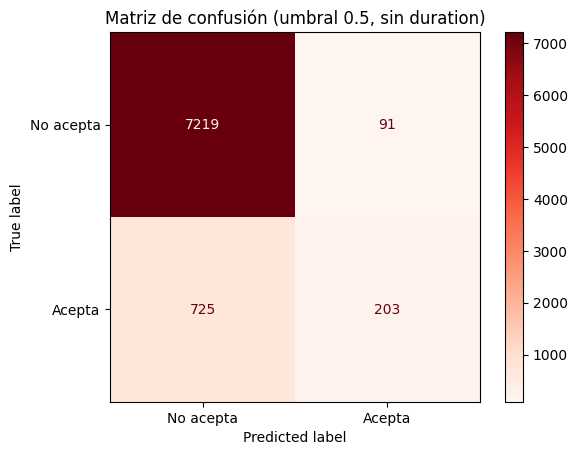

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_05,
    display_labels=['No acepta', 'Acepta'],
    cmap='Reds')
plt.title('Matriz de confusión (umbral 0.5, sin duration)')
plt.show()

In [10]:
tn, fp, fn, tp = confusion_matrix(y_test, pred_05).ravel()
print('Verdaderos negativos (TN):', tn)
print('Falsos positivos (FP):', fp)
print('Falsos negativos (FN):', fn)
print('Verdaderos positivos (TP):', tp)

exactitud = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
sensibilidad = tp / (tp + fn)
especificidad = tn / (tn + fp)
f1 = 2 * precision * sensibilidad / (precision + sensibilidad)

print()
print('Exactitud:', round(exactitud, 3))
print('Precisión:', round(precision, 3))
print('Sensibilidad:', round(sensibilidad, 3))
print('Especificidad:', round(especificidad, 3))
print('F1:', round(f1, 3))

Verdaderos negativos (TN): 7219
Falsos positivos (FP): 91
Falsos negativos (FN): 725
Verdaderos positivos (TP): 203

Exactitud: 0.901
Precisión: 0.69
Sensibilidad: 0.219
Especificidad: 0.988
F1: 0.332


La sensibilidad (22%) es la más importante para el banco porque mide cuántos de los clientes que sí habrían aceptado logra encontrar, cada falso negativo es un ingreso perdido, mientras que un falso positivo solo cuesta una llamada. La exactitud (90%) y la especificidad (99%) se ven muy bien pero están dominadas por la clase mayoritaria, y con umbral 0.5 el modelo es demasiado conservador, acierta cuando llama (precisión aproximada 69%) pero deja escapar a casi 4 de cada 5 interesados.

## 4. Curva ROC y curva de precisión contra sensibilidad

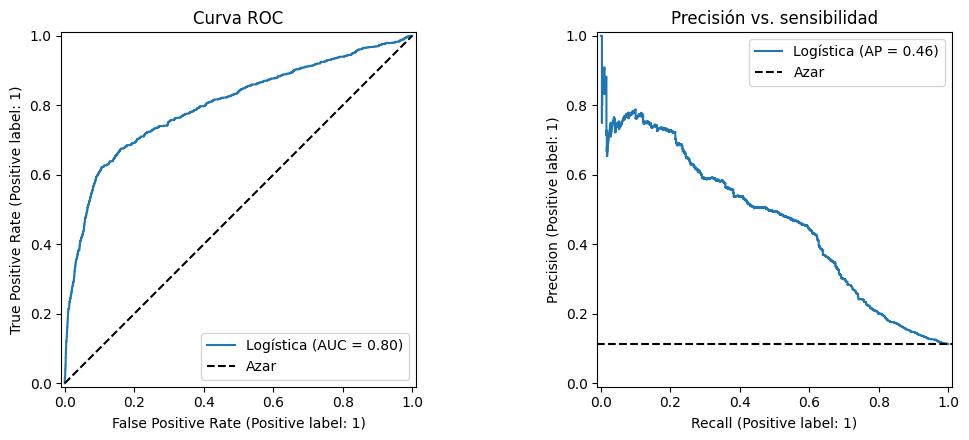

AUC (ROC): 0.801
Precisión promedio (AP): 0.465


In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

RocCurveDisplay.from_predictions(y_test, prob_test, ax=ejes[0], name='Logística')
ejes[0].plot([0, 1], [0, 1], 'k--', label='Azar')
ejes[0].set_title('Curva ROC')
ejes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, prob_test, ax=ejes[1], name='Logística')
ejes[1].axhline(y_test.mean(), color='k', linestyle='--', label='Azar')
ejes[1].set_title('Precisión vs. sensibilidad')
ejes[1].legend()

plt.tight_layout()
plt.show()

print('AUC (ROC):', round(roc_auc_score(y_test, prob_test), 3))
print('Precisión promedio (AP):', round(average_precision_score(y_test, prob_test), 3))

La curva ROC logra un buen resultado (AUC aproximadamente 0.80) porque la tasa de falsos positivos se divide entre los muchísimos negativos, así que suaviza el costo de equivocarse. La curva de precisión-sensibilidad muestra la realidad con pocos positivos, la precisión cae rápido al subir la sensibilidad y la precisión promedio es solo ≈ 0.46 frente a un azar de 0.11, es decir, muchas de las llamadas adicionales serían a clientes que no aceptan.

## 5. Umbral óptimo por rentabilidad
Cada llamada cuesta 5 y, si el cliente acepta, deja un ingreso de 50. Conviene llamar cuando la ganancia esperada es positiva.


In [12]:
costo = 5
ingreso = 50
umbral_optimo = costo / ingreso
print('Umbral óptimo:', umbral_optimo)

def ganancia(umbral):
    llamamos = prob_test >= umbral
    aceptan = (llamamos == True) & (y_test.values == 1)
    return ingreso * aceptan.sum() - costo * llamamos.sum()

print('Ganancia con umbral 0.5 :', ganancia(0.5))
print('Ganancia con umbral 0.10:', ganancia(umbral_optimo))
print('Ganancia llamando a todos:', ganancia(0))
print('Llamadas con umbral 0.5 :', (prob_test >= 0.5).sum())
print('Llamadas con umbral 0.10:', (prob_test >= 0.10).sum())

Umbral óptimo: 0.1
Ganancia con umbral 0.5 : 8680
Ganancia con umbral 0.10: 22100
Ganancia llamando a todos: 5210
Llamadas con umbral 0.5 : 294
Llamadas con umbral 0.10: 1900


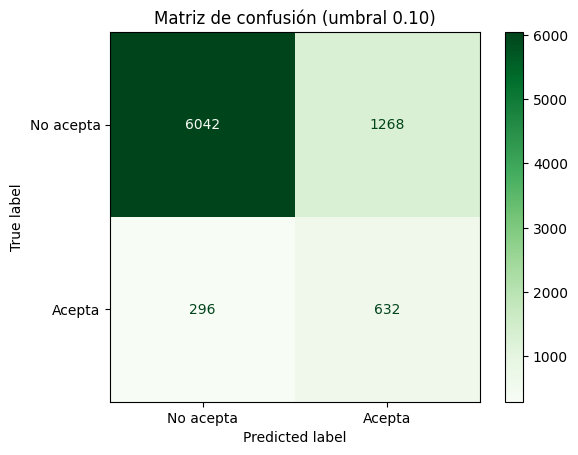

In [13]:
pred_010 = (prob_test >= umbral_optimo).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_010,
    display_labels=['No acepta', 'Acepta'],
    cmap='Greens')
plt.title('Matriz de confusión (umbral 0.10)')
plt.show()

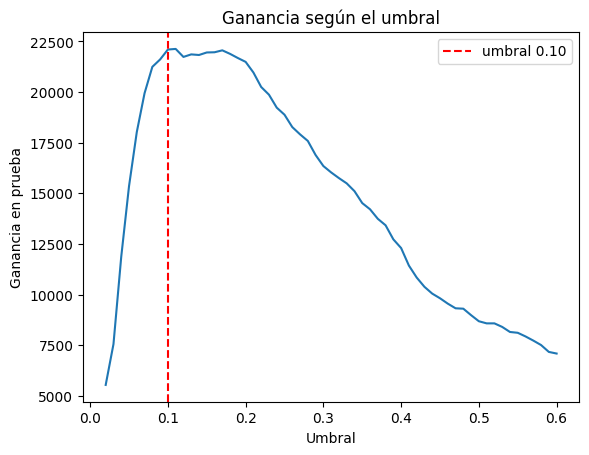

In [14]:
umbrales = np.arange(0.02, 0.61, 0.01)
ganancias = []
for u in umbrales:
    ganancias.append(ganancia(u))

plt.plot(umbrales, ganancias)
plt.axvline(umbral_optimo, color='red', linestyle='--', label='umbral 0.10')
plt.xlabel('Umbral')
plt.ylabel('Ganancia en prueba')
plt.title('Ganancia según el umbral')
plt.legend()
plt.show()

Conviene llamar cuando la probabilidad supera 5/50 = 0.10, porque a partir de ahí el ingreso esperado (p·50) supera el costo de la llamada. En prueba, el umbral 0.10 da una ganancia de = 22.100 contra 8.700 con el umbral 0.5 (y ≈ 5.200 si se llama a todos), y la curva muestra que el máximo empírico coincide con ese valor teórico. Con 0.10 baja la exactitud (81%), pero eso no importa porque el objetivo es el dinero, no acertar la clase.

## 6. Repetir el punto 3 incluyendo la variable eliminada (duration)

In [15]:
X2 = df.drop(columns=['y'])
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, stratify=y, random_state=42)

cols_cat2 = []
cols_num2 = []
for col in X2.columns:
    if X2[col].dtype == 'int64' or X2[col].dtype == 'float64':
        cols_num2.append(col)
    else:
        cols_cat2.append(col)

preproceso2 = ColumnTransformer([
    ('categoricas', OneHotEncoder(handle_unknown='ignore'), cols_cat2),
    ('numericas', StandardScaler(), cols_num2)
])
modelo2 = Pipeline([
    ('preproceso', preproceso2),
    ('logistica', LogisticRegression(max_iter=3000))
])
modelo2.fit(X2_train, y2_train)
prob2 = modelo2.predict_proba(X2_test)[:, 1]
pred2 = (prob2 >= 0.5).astype(int)

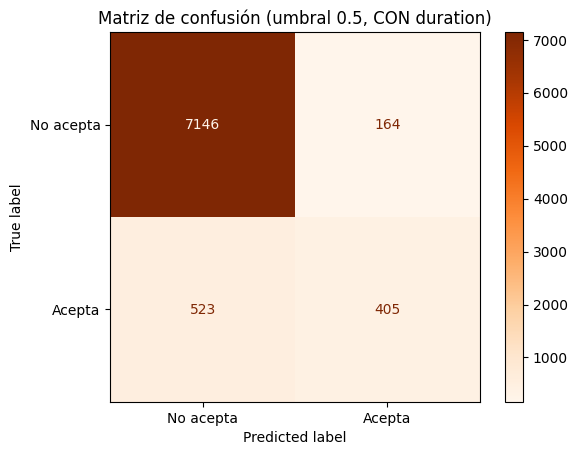

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y2_test, pred2,
    display_labels=['No acepta', 'Acepta'],
    cmap='Oranges')
plt.title('Matriz de confusión (umbral 0.5, CON duration)')
plt.show()

In [17]:
tn2, fp2, fn2, tp2 = confusion_matrix(y2_test, pred2).ravel()

exactitud2 = (tp2 + tn2) / (tp2 + tn2 + fp2 + fn2)
precision2 = tp2 / (tp2 + fp2)
sensibilidad2 = tp2 / (tp2 + fn2)
especificidad2 = tn2 / (tn2 + fp2)
f1_2 = 2 * precision2 * sensibilidad2 / (precision2 + sensibilidad2)

print('Métrica        SIN duration   CON duration')
print('Exactitud     ', round(exactitud, 3), '        ', round(exactitud2, 3))
print('Precisión     ', round(precision, 3), '        ', round(precision2, 3))
print('Sensibilidad  ', round(sensibilidad, 3), '        ', round(sensibilidad2, 3))
print('Especificidad ', round(especificidad, 3), '        ', round(especificidad2, 3))
print('F1            ', round(f1, 3), '        ', round(f1_2, 3))
print('AUC (ROC)     ', round(roc_auc_score(y_test, prob_test), 3), '        ', round(roc_auc_score(y2_test, prob2), 3))

Métrica        SIN duration   CON duration
Exactitud      0.901          0.917
Precisión      0.69          0.712
Sensibilidad   0.219          0.436
Especificidad  0.988          0.978
F1             0.332          0.541
AUC (ROC)      0.801          0.942


Al incluir duration todas las métricas mejoran mucho (sensibilidad aproximandamente 22 % a 44 %, AUC = 0.80 a 0.94, F1 = 0.33 a 0.54). Esa mejora no le sirve al banco, es una ilusión porque la duración solo se conoce al terminar la llamada, cuando ya no hay decisión que tomar; un modelo así no puede usarse para elegir a quién llamar y su rendimiento real sería el del modelo sin duration.

# Referencias

Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

# Declaración de uso de la IA

Para esta practica se utilizo la inteligencia artificial Anthropic Claude como herramienta de asistencia para la revision, edicion y mejora del formato de texto asi como el apoyo en la toma de sugerencias para la parte del codigo y la correccion de errores.